# 03 – Phân cụm khách hàng bằng các thuật toán cổ điển: K-Means, Hierarchical (Ward), GMM

**Đầu vào:** `outputs/rfm_model_input.csv`, gồm 4.320 khách hàng × 3 đặc trưng `Recency_s, Frequency_s, Monetary_s` (đã log1p và z-score, xem notebook 02).

**Nội dung:**
1. Tóm tắt nguyên lý ba thuật toán và các chỉ số đánh giá
2. K-Means: chọn số cụm K bằng Elbow, Silhouette, Davies-Bouldin, Calinski-Harabasz
3. Hierarchical clustering: dendrogram và so sánh các kiểu liên kết (linkage)
4. Gaussian Mixture Model: chọn K bằng BIC, xử lý hiện tượng suy biến hiệp phương sai
5. So sánh ba thuật toán tại cùng K: chỉ số, thời gian, độ ổn định, hồ sơ cụm, mức độ đồng thuận với baseline RFM scoring
6. Thử nghiệm với bộ đặc trưng RFM mở rộng (6 chiều)

## 1. Tóm tắt nguyên lý thuật toán và chỉ số đánh giá

| Thuật toán | Ý tưởng | Hàm mục tiêu / tiêu chí | Giả định về cụm | Độ phức tạp |
|---|---|---|---|---|
| **K-Means** (khởi tạo k-means++) | Lặp lại 2 bước: gán mỗi điểm vào tâm gần nhất, rồi cập nhật tâm bằng trung bình các điểm trong cụm | Cực tiểu tổng bình phương khoảng cách trong cụm (inertia/WCSS): $\sum_{k}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^2$ | Cụm lồi, dạng cầu, kích thước tương đương; nhạy với ngoại lệ | $O(n\cdot K\cdot d\cdot t)$ |
| **Agglomerative (Ward)** | Bắt đầu với mỗi điểm là một cụm, lần lượt gộp hai cụm "gần" nhau nhất cho đến khi còn K cụm; kết quả là cây phân cấp (dendrogram) | Ward: gộp cặp cụm làm **tăng ít nhất** tổng phương sai trong cụm. Ngoài ra có các kiểu liên kết single, complete, average | Phụ thuộc kiểu liên kết; Ward cho cụm gọn, gần giống K-Means | Thời gian $O(n^2\log n)$, bộ nhớ $O(n^2)$ |
| **GMM** (thuật toán EM) | Coi dữ liệu được sinh từ hỗn hợp K phân phối chuẩn nhiều chiều. Bước E tính xác suất mỗi điểm thuộc mỗi thành phần; bước M cập nhật $\pi_k, \mu_k, \Sigma_k$ | Cực đại log-likelihood $\sum_i \log\sum_k \pi_k\,\mathcal N(x_i\mid\mu_k,\Sigma_k)$; chọn K bằng $BIC = -2\ln L + p\ln n$ | Cụm hình elip, kích thước và hướng tùy ý; **gán mềm** (cho xác suất) | $O(n\cdot K\cdot d^2\cdot t)$ |

**Chỉ số đánh giá nội bộ** (không cần nhãn thật):
- **Silhouette** $s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}\in[-1,1]$, trong đó $a$ là khoảng cách trung bình tới các điểm cùng cụm và $b$ là khoảng cách trung bình tới cụm gần nhất khác. **Càng cao càng tốt.**
- **Davies-Bouldin** là trung bình, trên các cụm, của tỉ số lớn nhất $\frac{s_i+s_j}{d(\mu_i,\mu_j)}$ (độ phân tán / khoảng cách giữa hai tâm). **Càng thấp càng tốt.**
- **Calinski-Harabasz** là tỉ số giữa phương sai giữa các cụm và phương sai trong cụm, có hiệu chỉnh theo bậc tự do. **Càng cao càng tốt.**

**Chỉ số so sánh hai cách phân cụm:** **ARI** (Adjusted Rand Index; 1 là trùng hoàn toàn, ≈0 là ngẫu nhiên) và **NMI** (Normalized Mutual Information, từ 0 đến 1). Hai chỉ số này dùng để đo độ ổn định và mức đồng thuận giữa các thuật toán, cũng như với baseline.

## 2. Đọc dữ liệu và thiết lập thực nghiệm

In [1]:
import sys, warnings, time
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples

from src.cluster_utils import (internal_metrics, timed_fit, relabel_by_value, bootstrap_stability,
                               agreement, profile, name_clusters)
from src import viz
viz.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
OUT = Path("../outputs")
SEED = 42
K_RANGE = range(2, 11)

X = pd.read_csv(OUT / "rfm_model_input.csv", index_col=0)            # 3 cột *_s
rfm = pd.read_csv(OUT / "rfm_features.csv", index_col=0)               # giá trị gốc để diễn giải
rule = pd.read_csv(OUT / "rfm_scores.csv", index_col=0)["Segment_Rule"] # baseline
assert (X.index == rfm.index).all() and (X.index == rule.index).all()
Xv = X.values
print("Ma trận đầu vào:", X.shape, "| seed =", SEED)
X.describe().T[["mean", "std", "min", "max"]]

Ma trận đầu vào: (4320, 3) | seed = 42


,mean,std,min,max
Recency_s,0.000,1.000,-2.745,1.535
Frequency_s,0.000,1.000,-0.954,5.850
Monetary_s,-0.000,1.000,-4.158,4.789


## 3. K-Means
### 3.1 Khảo sát số cụm K từ 2 đến 10

In [2]:
rows = []
for k in K_RANGE:
    m, lab, t = timed_fit(lambda: KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED), Xv)
    rows.append({"K": k, "Inertia": m.inertia_, **internal_metrics(Xv, lab), "Thời gian (s)": t})
km_scan = pd.DataFrame(rows).set_index("K")
km_scan

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Thời gian (s)
K,,,,,
2,"6,459.059",0.434,0.892,"4,345.999",0.041
3,"4,849.426",0.339,1.044,"3,610.051",0.017
4,"3,933.949",0.339,1.013,"3,300.917",0.025
5,"3,308.354",0.318,0.992,"3,147.120",0.028
6,"2,855.428",0.313,1.015,"3,053.246",0.033
7,"2,557.063",0.308,0.976,"2,924.467",0.032
8,"2,344.338",0.292,1.011,"2,789.379",0.041
9,"2,162.368",0.279,1.020,"2,690.883",0.042
10,"2,004.578",0.276,1.016,"2,617.245",0.054


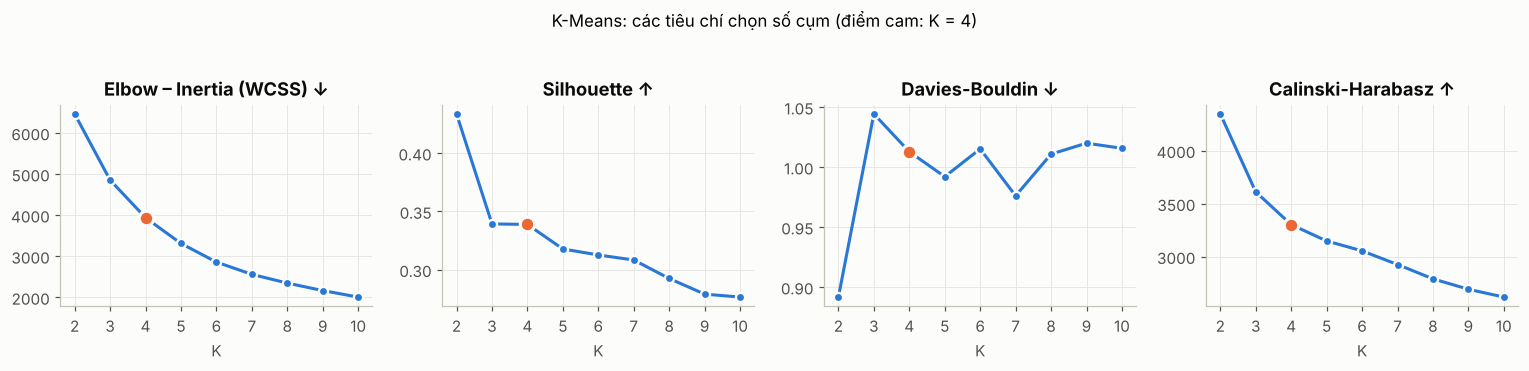

In [3]:
def plot_scan(scan, title, fname, first=("Inertia", "Elbow – Inertia (WCSS) ↓")):
    panels = [first, ("Silhouette", "Silhouette ↑"), ("Davies-Bouldin", "Davies-Bouldin ↓"),
              ("Calinski-Harabasz", "Calinski-Harabasz ↑")]
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
    for ax, (col, t) in zip(axes, panels):
        ax.plot(scan.index, scan[col], color=viz.MAIN, marker="o", markersize=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
        ax.scatter([4], [scan.loc[4, col]], s=90, color=viz.ACCENT, zorder=3, edgecolor="#fcfcfb", linewidth=2)
        ax.set_title(t); ax.set_xlabel("K"); ax.set_xticks(list(scan.index))
    fig.suptitle(title, y=1.04, fontsize=11)
    fig.tight_layout(); viz.save(fig, fname); plt.show()

plot_scan(km_scan, "K-Means: các tiêu chí chọn số cụm (điểm cam: K = 4)", "fig15_kmeans_k_selection")

In [4]:
# Mức giảm inertia khi tăng K (hỗ trợ đọc điểm khuỷu tay)
drop = (-km_scan["Inertia"].pct_change() * 100).round(1)
drop.rename("% inertia giảm so với K-1").to_frame().T

K,2,3,4,5,6,7,8,9,10
% inertia giảm so với K-1,NaN,24.900,18.900,15.900,13.700,10.400,8.300,7.800,7.300


**Nhận xét – chọn số cụm K:**
- **Silhouette cao nhất ở K = 2 (0,434)**. Tuy nhiên K = 2 chỉ chia khách thành "đang hoạt động, giá trị cao" (1.651 khách) và "ít hoạt động, giá trị thấp" (2.669 khách). Cách chia này quá thô để xây dựng chiến lược marketing. Silhouette thường ưu tiên K nhỏ khi dữ liệu là một dải liên tục, như đã quan sát ở notebook 02.
- **K = 3 và K = 4 có Silhouette bằng nhau (0,339)**, còn từ K = 5 trở đi chỉ số giảm dần. **Elbow:** inertia giảm 24,9% khi đi từ K=2 lên 3, giảm 18,9% từ 3 lên 4, và các mức giảm sau đó nhỏ dần (≤ 15,9%). Đường cong không có "khuỷu tay" sắc nét, nhưng phần lợi ích chủ yếu nằm ở K ≤ 4.
- **Davies-Bouldin** dao động hẹp (0,98–1,04) với K ≥ 3, nên không phân biệt rõ các K. **Calinski-Harabasz** giảm đơn điệu, nên cũng không giúp chọn K.
- So sánh K = 3 với K = 4: ở K = 3, nhóm "khách mới mua gần đây nhưng giá trị thấp" bị gộp chung với nhóm "trung thành giá trị trung bình". K = 4 tách được hai nhóm này, mà về mặt kinh doanh chúng cần hai chiến lược khác nhau (chào đón/kích hoạt so với duy trì).
- → **Chọn K = 4.** Ba căn cứ: Silhouette ngang với K = 3, khả năng diễn giải tốt hơn, và (như sẽ thấy ở mục 5) BIC của GMM cũng đạt cực tiểu cục bộ tại K = 4. Để so sánh công bằng, cả ba thuật toán đều dùng K = 4.

### 3.2 Huấn luyện K-Means với K = 4

In [5]:
K = 4
km, km_lab, km_time = timed_fit(lambda: KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=SEED), Xv)
km_lab = relabel_by_value(km_lab, rfm["Monetary"])
print(f"Số vòng lặp hội tụ: {km.n_iter_} | thời gian: {km_time:.3f}s | kích thước cụm: {np.bincount(km_lab)}")

# Đưa tâm cụm về thang đo gốc: z-score -> log1p -> giá trị thật (đảo ngược phép biến đổi)
log_core = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
mu, sd = log_core.mean().values, log_core.std(ddof=0).values
centers = pd.DataFrame(X.assign(c=km_lab).groupby("c").mean().values, columns=["R_s", "F_s", "M_s"])
centers_raw = pd.DataFrame(np.expm1(centers.values * sd + mu), columns=["Recency (ngày)", "Frequency (đơn)", "Monetary (£)"])
pd.concat([centers, centers_raw], axis=1).rename_axis("Cụm")

Số vòng lặp hội tụ: 26 | thời gian: 0.023s | kích thước cụm: [ 685 1192  803 1640]


,R_s,F_s,M_s,Recency (ngày),Frequency (đơn),Monetary (£)
Cụm,,,,,,
0,-1.268,1.693,1.429,6.727,11.156,"4,190.126"
1,0.119,0.335,0.529,51.671,3.815,"1,359.910"
2,-0.870,-0.359,-0.391,12.404,2.001,430.099
3,0.869,-0.775,-0.789,147.937,1.260,261.196


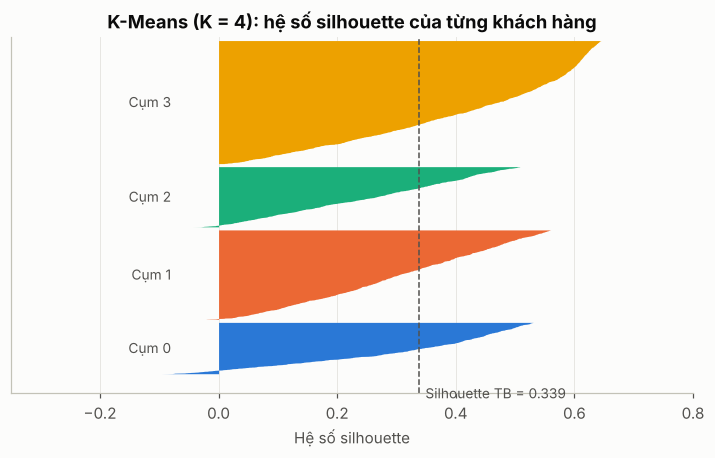

,0,1,2,3
Silhouette TB cụm,0.303 (âm: 7.2%),0.302 (âm: 0.9%),0.254 (âm: 2.7%),0.422 (âm: 0.0%)


In [6]:
# Biểu đồ silhouette từng điểm: kiểm tra chất lượng của từng cụm
sil = silhouette_samples(Xv, km_lab)
fig, ax = plt.subplots(figsize=(8, 4.2))
y0 = 0
for c in range(K):
    v = np.sort(sil[km_lab == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=viz.PALETTE[c], linewidth=0)
    ax.text(-0.08, y0 + len(v) / 2, f"Cụm {c}", va="center", ha="right", fontsize=9, color=viz.INK2)
    y0 += len(v) + 40
ax.axvline(sil.mean(), color=viz.INK2, linestyle="--", linewidth=1)
ax.text(sil.mean() + .01, -150, f"Silhouette TB = {sil.mean():.3f}", color=viz.INK2, fontsize=9, va="top")
ax.set_ylim(-260, y0)
ax.set_yticks([]); ax.set_xlabel("Hệ số silhouette"); ax.set_xlim(-0.35, 0.8)
ax.set_title("K-Means (K = 4): hệ số silhouette của từng khách hàng")
viz.save(fig, "fig16_kmeans_silhouette"); plt.show()
pd.Series({c: f"{sil[km_lab==c].mean():.3f} (âm: {100*(sil[km_lab==c]<0).mean():.1f}%)" for c in range(K)}, name="Silhouette TB cụm").to_frame().T

**Nhận xét – K-Means (K = 4):**
- Thuật toán hội tụ sau 26 vòng lặp, mất khoảng 0,03 giây. Các cụm có kích thước khá cân đối (685 / 1.192 / 803 / 1.640 khách).
- Đưa tâm cụm về thang đo gốc cho ra bốn chân dung khách hàng rõ ràng:
  - **Cụm 0:** mua cách đây khoảng 7 ngày, khoảng 11 đơn, khoảng 4.190 £ (nhóm VIP)
  - **Cụm 1:** khoảng 52 ngày, khoảng 4 đơn, khoảng 1.360 £
  - **Cụm 2:** khoảng 12 ngày, khoảng 2 đơn, khoảng 430 £ (khách mới)
  - **Cụm 3:** khoảng 148 ngày, khoảng 1 đơn, khoảng 261 £ (ngủ đông)
  Tâm cụm ở đây là trung bình trong không gian log, nên khi đảo ngược sẽ gần với trung bình nhân hơn là trung bình cộng.
- **Biểu đồ silhouette:** cụm 3 (ngủ đông) tách biệt tốt nhất (0,42, không có điểm âm). Cụm 0 (VIP) có 7,2% điểm silhouette âm: đó là những khách nằm ở rìa, gần với cụm 1. Điều này phù hợp với nhận xét rằng dữ liệu là một dải liên tục, và ranh giới giữa "VIP" và "trung thành" mang tính tương đối.

## 4. Hierarchical Clustering (Agglomerative)
### 4.1 Dendrogram (liên kết Ward)

Thời gian tính ma trận liên kết Ward cho 4,320 điểm: 0.41s


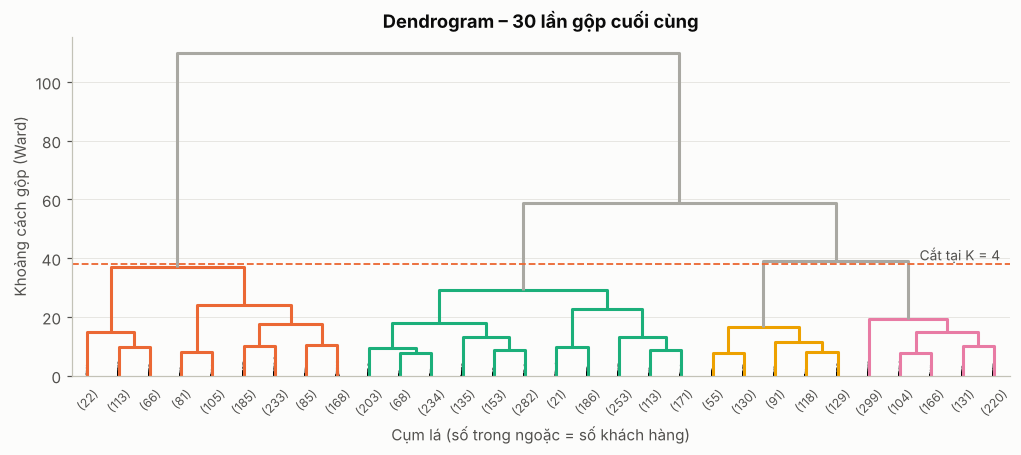

Khoảng cách 6 lần gộp cuối (từ K=7 về K=1): [ 24.1  29.2  37.2  39.2  58.7 109.8]


In [7]:
t0 = time.perf_counter()
Z = linkage(Xv, method="ward")
print(f"Thời gian tính ma trận liên kết Ward cho {len(Xv):,} điểm: {time.perf_counter() - t0:.2f}s")

fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=Z[-4, 2] + 1e-9, above_threshold_color=viz.GREY,
           leaf_font_size=8, show_contracted=True)
cut = (Z[-4, 2] + Z[-3, 2]) / 2
ax.axhline(cut, color=viz.ACCENT, linestyle="--", linewidth=1.2)
ax.text(ax.get_xlim()[1] * .99, cut * 1.03, "Cắt tại K = 4", ha="right", color=viz.INK2, fontsize=9)
ax.set_ylabel("Khoảng cách gộp (Ward)"); ax.set_xlabel("Cụm lá (số trong ngoặc = số khách hàng)")
ax.set_title("Dendrogram – 30 lần gộp cuối cùng"); ax.grid(axis="x", visible=False)
viz.save(fig, "fig17_dendrogram"); plt.show()
print("Khoảng cách 6 lần gộp cuối (từ K=7 về K=1):", np.round(Z[-6:, 2], 1))

### 4.2 Khảo sát số cụm và so sánh các kiểu liên kết

,Merge distance,Silhouette,Davies-Bouldin,Calinski-Harabasz,Thời gian (s)
K,,,,,
2,109.826,0.437,0.843,"3,758.267",0.404
3,58.710,0.289,1.210,"3,215.285",0.330
4,39.151,0.269,1.029,"2,761.370",0.404
5,37.183,0.272,1.046,"2,651.420",0.368
6,29.169,0.245,1.209,"2,502.645",0.442
7,24.113,0.239,1.169,"2,353.911",0.366
8,22.833,0.223,1.069,"2,264.862",0.360
9,19.381,0.205,1.079,"2,164.509",0.376
10,18.128,0.188,1.142,"2,086.752",0.372


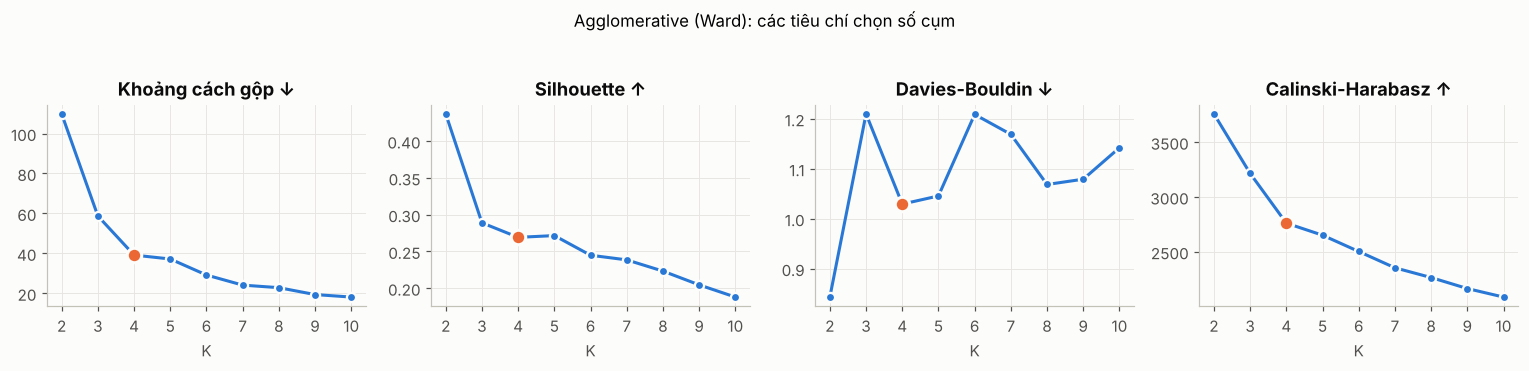

In [8]:
rows = []
for k in K_RANGE:
    _, lab, t = timed_fit(lambda: AgglomerativeClustering(n_clusters=k, linkage="ward"), Xv)
    rows.append({"K": k, "Merge distance": Z[-(k - 1), 2], **internal_metrics(Xv, lab), "Thời gian (s)": t})
hc_scan = pd.DataFrame(rows).set_index("K")
display(hc_scan)
plot_scan(hc_scan, "Agglomerative (Ward): các tiêu chí chọn số cụm", "fig18_hc_k_selection",
          first=("Merge distance", "Khoảng cách gộp ↓"))

In [9]:
rows = []
for lk in ["ward", "complete", "average", "single"]:
    _, lab, t = timed_fit(lambda: AgglomerativeClustering(n_clusters=K, linkage=lk), Xv)
    sizes = np.sort(np.bincount(lab))[::-1]
    rows.append({"Linkage": lk, **internal_metrics(Xv, lab), "Kích thước cụm": sizes.tolist(),
                 "% cụm lớn nhất": 100 * sizes[0] / len(lab), "Thời gian (s)": t})
pd.DataFrame(rows).set_index("Linkage")

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Kích thước cụm,% cụm lớn nhất,Thời gian (s)
Linkage,,,,,,
ward,0.269,1.029,"2,761.370","[1819, 1058, 920, 523]",42.106,0.357
complete,0.263,0.916,"1,689.717","[2284, 1714, 315, 7]",52.870,0.421
average,0.432,0.653,244.215,"[4230, 87, 2, 1]",97.917,0.468
single,0.440,0.337,14.958,"[4316, 2, 1, 1]",99.907,0.048


**Nhận xét – Hierarchical clustering:**
- **Dendrogram:** khoảng cách gộp tăng mạnh nhất ở hai lần gộp cuối (58,7 và 109,8). Nếu chỉ dựa vào "khoảng nhảy lớn nhất" thì dendrogram gợi ý K = 2 hoặc 3. Khoảng cách từ 4 cụm về 3 cụm chỉ là 39,2, gần bằng mức 37,2 của lần gộp trước, tức là ranh giới giữa 4 cụm không thật sự sắc nét. Điều này một lần nữa xác nhận rằng dữ liệu không có cấu trúc cụm tách biệt rõ.
- **Theo K**, Ward có Silhouette thấp hơn K-Means ở mọi K ≥ 3 (0,269 so với 0,339 tại K = 4). Lý do: Ward tối ưu cục bộ theo từng bước gộp và không bao giờ "sửa" lại một quyết định gộp đã làm, trong khi K-Means tối ưu trực tiếp tổng phương sai trong cụm.
- **So sánh kiểu liên kết (K = 4):** average và single linkage cho Silhouette và Davies-Bouldin rất "đẹp" (0,43–0,44 và 0,34–0,65), nhưng thực chất **gần như toàn bộ khách nằm trong một cụm** (97,9% và 99,9%); các cụm còn lại chỉ có 1–87 điểm ngoại lệ. Đây là **hiệu ứng chuỗi (chaining)** của single linkage. Ví dụ này cho thấy **không thể chỉ nhìn vào chỉ số nội bộ** mà phải xem cả kích thước cụm. Complete linkage cũng tạo ra một cụm chỉ có 7 khách.
- → Chọn **Ward linkage** để so sánh với các thuật toán khác. Thời gian chạy khoảng 0,35 giây, chậm hơn K-Means khoảng 14 lần, và độ phức tạp bộ nhớ $O(n^2)$ khiến Ward khó áp dụng khi dữ liệu lên tới hàng trăm nghìn khách.

In [10]:
hc, hc_lab, hc_time = timed_fit(lambda: AgglomerativeClustering(n_clusters=K, linkage="ward"), Xv)
hc_lab = relabel_by_value(hc_lab, rfm["Monetary"])
print("Kích thước cụm (Ward, K=4):", np.bincount(hc_lab), f"| thời gian: {hc_time:.2f}s")

Kích thước cụm (Ward, K=4): [1058  920  523 1819] | thời gian: 0.37s


## 5. Gaussian Mixture Model (GMM)
### 5.1 Phát hiện: GMM bị suy biến với cài đặt mặc định
Với tham số mặc định (`reg_covar = 1e-6`), BIC giảm liên tục khi tăng K, và xuất hiện một cụm có kích thước rất "tròn". Phần dưới đây kiểm tra hiện tượng này.

In [11]:
g_def = GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=SEED).fit(Xv)
lab_def = g_def.predict(Xv)
print("Kích thước cụm (mặc định):", np.bincount(lab_def))
ct = pd.crosstab(lab_def, rfm["Frequency"].clip(upper=5).replace(5, "≥5"), rownames=["Cụm GMM"], colnames=["Frequency"])
display(ct)
c1 = ct[1].idxmax()   # cụm chứa phần lớn khách mua đúng 1 lần
print(f"Phương sai của Frequency_s trong cụm {c1}: {g_def.covariances_[c1][1, 1]:.2e}  (≈ 0 → suy biến)")

Kích thước cụm (mặc định): [1130 1493  868  829]


Frequency,1,2,3,4,≥5
Cụm GMM,,,,,
0,0,0,451,345,334
1,1493,0,0,0,0
2,0,0,51,50,767
3,0,829,0,0,0


Phương sai của Frequency_s trong cụm 1: 1.00e-06  (≈ 0 → suy biến)


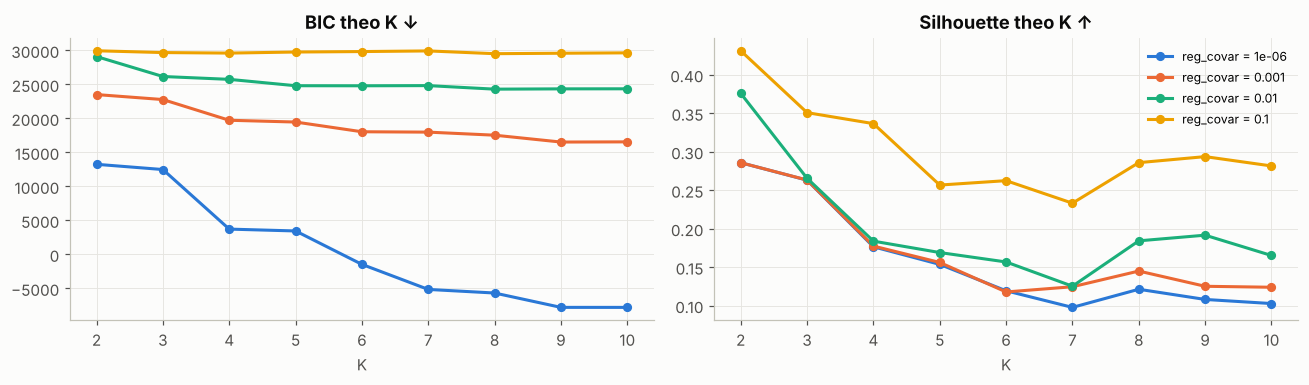

reg_covar,0.000,0.001,0.010,0.100
K,,,,
2,"13,252.000","23,512.000","29,104.000","29,956.000"
3,"12,484.000","22,780.000","26,170.000","29,692.000"
4,"3,721.000","19,732.000","25,751.000","29,614.000"
5,"3,448.000","19,471.000","24,814.000","29,770.000"
6,"-1,468.000","18,041.000","24,804.000","29,838.000"
7,"-5,153.000","17,986.000","24,829.000","29,933.000"
8,"-5,680.000","17,537.000","24,309.000","29,526.000"
9,"-7,792.000","16,528.000","24,351.000","29,592.000"
10,"-7,795.000","16,554.000","24,361.000","29,650.000"


In [12]:
rows = []
for rc in [1e-6, 1e-3, 1e-2, 1e-1]:
    for k in K_RANGE:
        g = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=SEED, reg_covar=rc).fit(Xv)
        rows.append({"reg_covar": rc, "K": k, "BIC": g.bic(Xv), "Silhouette": internal_metrics(Xv, g.predict(Xv))["Silhouette"]})
gm_reg = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for i, rc in enumerate([1e-6, 1e-3, 1e-2, 1e-1]):
    d = gm_reg[gm_reg["reg_covar"] == rc]
    axes[0].plot(d["K"], d["BIC"], marker="o", markersize=5, color=viz.PALETTE[i], label=f"reg_covar = {rc:g}")
    axes[1].plot(d["K"], d["Silhouette"], marker="o", markersize=5, color=viz.PALETTE[i], label=f"reg_covar = {rc:g}")
axes[0].set_title("BIC theo K ↓"); axes[1].set_title("Silhouette theo K ↑")
for ax in axes: ax.set_xlabel("K"); ax.set_xticks(list(K_RANGE))
axes[1].legend(fontsize=8)
fig.tight_layout(); viz.save(fig, "fig19_gmm_reg_covar"); plt.show()
gm_reg.pivot(index="K", columns="reg_covar", values="BIC").round(0)

**Nhận xét – hiện tượng suy biến của GMM (phát hiện quan trọng):**
- Với tham số mặc định, GMM tạo ra **một cụm gồm đúng 1.493 khách có Frequency = 1** và **một cụm gồm đúng 829 khách có Frequency = 2**. Phương sai của Frequency_s trong các cụm này bằng 1e-6, tức là đúng bằng `reg_covar`.
- **Nguyên nhân:** Frequency là **biến đếm rời rạc**. Rất nhiều khách có cùng một giá trị, tạo thành các "mặt phẳng" dữ liệu. Một thành phần Gauss có thể "co" phương sai theo chiều này về gần 0, khiến mật độ xác suất (và likelihood) tiến tới vô cùng. Vì vậy BIC giảm mãi, thậm chí âm, khi K tăng. Đây là hiện tượng **suy biến hiệp phương sai (singular covariance)** đã biết của GMM/EM.
- **Cách xử lý:** tăng `reg_covar`, tức là cộng một hằng số vào đường chéo của mọi ma trận hiệp phương sai (tương đương đặt sàn cho phương sai). Khi `reg_covar = 0,1` (khoảng 10% phương sai của dữ liệu đã chuẩn hóa), BIC ổn định trở lại và Silhouette tăng từ khoảng 0,18 lên 0,34 tại K = 4.
- Ý nghĩa: cần **hiểu giả định của thuật toán** (GMM giả định dữ liệu liên tục) chứ không chỉ chạy với tham số mặc định. Một cách xử lý khác là "khử rời rạc" (dequantization), tức là cộng nhiễu đều vào biến đếm; nhóm đã thử cách này nhưng không chọn vì nó làm thay đổi dữ liệu đầu vào so với hai thuật toán còn lại.

### 5.2 Chọn kiểu ma trận hiệp phương sai và số cụm (reg_covar = 0.1)

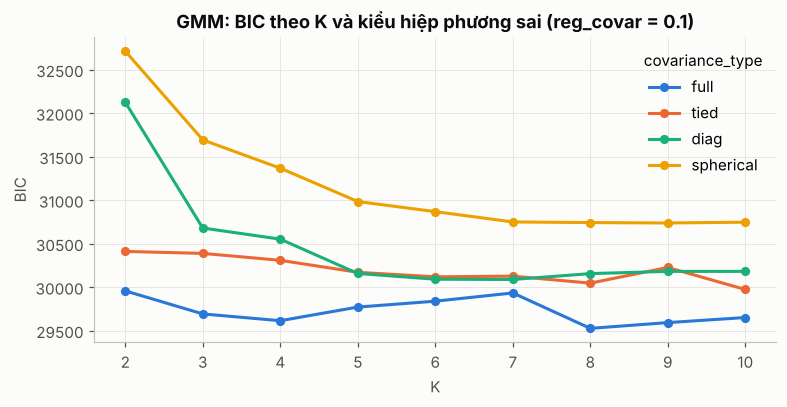

,BIC,AIC,Silhouette,Davies-Bouldin,Calinski-Harabasz,Thời gian (s)
K,,,,,,
2,"29,956.480","29,835.430",0.431,0.903,"4,110.296",0.040
3,"29,691.742","29,506.983",0.351,0.998,"3,403.738",0.047
4,"29,613.767","29,365.298",0.337,0.969,"3,099.738",0.048
5,"29,770.353","29,458.173",0.257,0.997,"2,068.411",0.204
6,"29,838.145","29,462.255",0.262,0.969,"1,878.176",0.235
7,"29,932.783","29,493.183",0.233,1.143,"1,685.690",0.326
8,"29,525.708","29,022.398",0.286,1.023,"2,661.761",0.282
9,"29,591.971","29,024.951",0.294,0.993,"2,541.896",0.234
10,"29,650.246","29,019.516",0.282,1.037,"2,398.296",0.217


In [13]:
REG = 0.1
rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in K_RANGE:
        t0 = time.perf_counter()
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=SEED, reg_covar=REG).fit(Xv)
        t = time.perf_counter() - t0
        lab = g.predict(Xv)
        rows.append({"Covariance": cov, "K": k, "BIC": g.bic(Xv), "AIC": g.aic(Xv), **internal_metrics(Xv, lab), "Thời gian (s)": t})
gm_scan = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, cov in enumerate(["full", "tied", "diag", "spherical"]):
    d = gm_scan[gm_scan["Covariance"] == cov]
    ax.plot(d["K"], d["BIC"], marker="o", markersize=5, color=viz.PALETTE[i], label=cov)
ax.set_xlabel("K"); ax.set_ylabel("BIC"); ax.set_xticks(list(K_RANGE)); ax.legend(title="covariance_type")
ax.set_title("GMM: BIC theo K và kiểu hiệp phương sai (reg_covar = 0.1)")
viz.save(fig, "fig20_gmm_bic"); plt.show()
gm_full = gm_scan[gm_scan["Covariance"] == "full"].set_index("K").drop(columns="Covariance")
gm_full

**Nhận xét – chọn cấu hình GMM:**
- Kiểu **full covariance** có BIC thấp nhất ở hầu hết các giá trị K. Lý do là các chiều R, F, M tương quan với nhau (F và M: 0,81), nên cụm có dạng elip nghiêng, mà chỉ ma trận hiệp phương sai đầy đủ mới mô tả được.
- Với full covariance, **BIC đạt cực tiểu cục bộ tại K = 4** (29.614) trong khoảng K = 2–7, rồi tăng dần đến K = 7. Từ K = 8 BIC lại giảm (29.526), nhưng lúc này mô hình bắt đầu "bám" vào các mức Frequency rời rạc (ở K lớn, phần regularization không còn đủ). Silhouette tại K = 4 vẫn tốt (0,337).
- AIC phạt độ phức tạp nhẹ hơn BIC nên giảm gần như liên tục. Nhóm chọn **BIC** vì đây là tiêu chí phổ biến hơn để chọn số thành phần cho GMM, và vì BIC ưu tiên mô hình đơn giản khi số mẫu lớn ($p\ln n$ so với $2p$).
- → Cấu hình được chọn: **GMM, covariance_type = full, K = 4, reg_covar = 0,1**.

Kích thước cụm (GMM full, K=4): [ 530 1363  541 1886] | thời gian: 0.05s | hội tụ: True


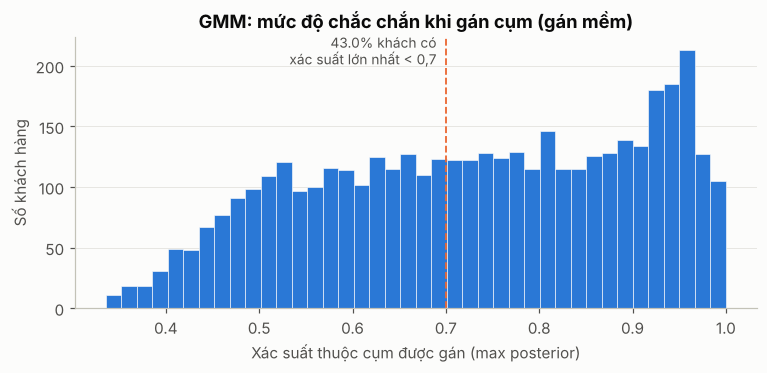

In [14]:
gm, gm_lab, gm_time = timed_fit(lambda: GaussianMixture(n_components=K, covariance_type="full", n_init=5,
                                                           random_state=SEED, reg_covar=REG), Xv)
proba = gm.predict_proba(Xv)
gm_lab = relabel_by_value(gm_lab, rfm["Monetary"])
maxp = proba.max(axis=1)
print("Kích thước cụm (GMM full, K=4):", np.bincount(gm_lab), f"| thời gian: {gm_time:.2f}s | hội tụ: {gm.converged_}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(maxp, bins=40, color=viz.MAIN, edgecolor="#fcfcfb", linewidth=.4)
ax.axvline(0.7, color=viz.ACCENT, linestyle="--", linewidth=1.2)
ax.text(0.69, ax.get_ylim()[1] * .9, f"{100*(maxp<0.7).mean():.1f}% khách có\nxác suất lớn nhất < 0,7", ha="right", color=viz.INK2, fontsize=9)
ax.set_xlabel("Xác suất thuộc cụm được gán (max posterior)"); ax.set_ylabel("Số khách hàng")
ax.set_title("GMM: mức độ chắc chắn khi gán cụm (gán mềm)"); ax.grid(axis="x", visible=False)
viz.save(fig, "fig21_gmm_posterior"); plt.show()

**Nhận xét – gán mềm của GMM:**
- Kích thước cụm là 530 / 1.363 / 541 / 1.886 khách. So với K-Means, cụm VIP của GMM "chặt" hơn (530 so với 685 khách), còn cụm ngủ đông lớn hơn.
- **Ưu điểm riêng của GMM:** cho biết **xác suất** mỗi khách thuộc từng cụm. Có tới **43% khách có xác suất lớn nhất < 0,7**, tức là nằm ở vùng giao giữa các cụm. Thông tin này có giá trị thực tế: có thể ưu tiên chăm sóc những khách "đang chuyển dịch" (ví dụ xác suất thuộc cụm trung thành giảm dần, xác suất thuộc cụm ngủ đông tăng dần), điều mà K-Means và Hierarchical (gán cứng) không cung cấp được.

## 6. So sánh ba thuật toán tại K = 4
### 6.1 Chỉ số nội bộ, thời gian và độ ổn định

In [15]:
models = {
    "K-Means": (lambda: KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=SEED), km_lab, km_time),
    "Agglomerative (Ward)": (lambda: AgglomerativeClustering(n_clusters=K, linkage="ward"), hc_lab, hc_time),
    "GMM (full)": (lambda: GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=SEED, reg_covar=REG), gm_lab, gm_time),
}
rows = []
for name, (mk, lab, t) in models.items():
    st_m, st_s = bootstrap_stability(mk, Xv, lab, n_runs=20, frac=.8, seed=SEED)
    sizes = np.bincount(lab)
    rows.append({"Thuật toán": name, **internal_metrics(Xv, lab), "Thời gian (s)": t,
                 "Ổn định (ARI TB)": st_m, "Ổn định (ARI std)": st_s,
                 "Cụm nhỏ nhất (%)": 100 * sizes.min() / len(lab), "Cụm lớn nhất (%)": 100 * sizes.max() / len(lab),
                 "ARI với baseline RFM": agreement(lab, rule)["ARI"], "NMI với baseline RFM": agreement(lab, rule)["NMI"]})
cmp = pd.DataFrame(rows).set_index("Thuật toán")
cmp

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Thời gian (s),Ổn định (ARI TB),Ổn định (ARI std),Cụm nhỏ nhất (%),Cụm lớn nhất (%),ARI với baseline RFM,NMI với baseline RFM
Thuật toán,,,,,,,,,,
K-Means,0.339,1.013,"3,300.917",0.023,0.954,0.042,15.856,37.963,0.352,0.513
Agglomerative (Ward),0.269,1.029,"2,761.370",0.372,0.436,0.091,12.106,42.106,0.357,0.479
GMM (full),0.337,0.969,"3,099.738",0.050,0.854,0.149,12.269,43.657,0.295,0.496


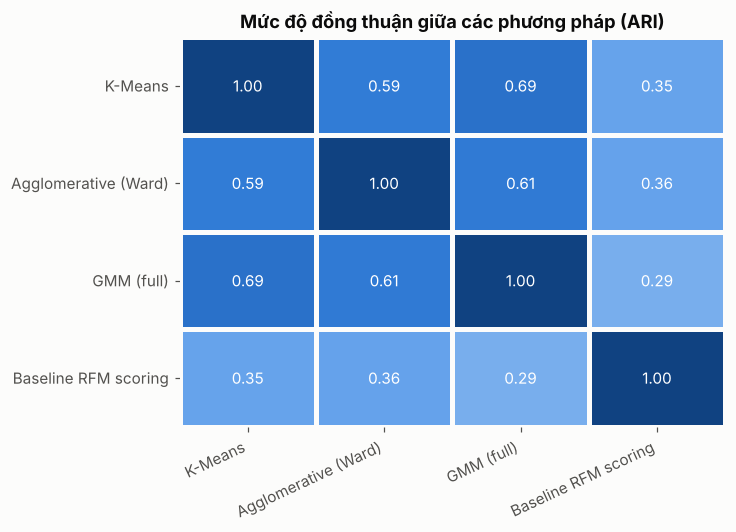

In [16]:
labels_all = {"K-Means": km_lab, "Agglomerative (Ward)": hc_lab, "GMM (full)": gm_lab, "Baseline RFM scoring": rule.values}
names = list(labels_all)
ari = pd.DataFrame([[agreement(labels_all[a], labels_all[b])["ARI"] for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
sns.heatmap(ari, annot=True, fmt=".2f", cmap=viz.SEQ_CMAP, vmin=0, vmax=1, ax=ax, cbar=False,
            linewidths=2, linecolor="#fcfcfb", annot_kws={"size": 10})
ax.set_title("Mức độ đồng thuận giữa các phương pháp (ARI)")
plt.xticks(rotation=25, ha="right"); plt.yticks(rotation=0)
viz.save(fig, "fig22_ari_agreement"); plt.show()

**Nhận xét – so sánh định lượng (K = 4):**

| Tiêu chí | Tốt nhất | Ghi chú |
|---|---|---|
| Silhouette ↑ | K-Means (0,339) ≈ GMM (0,337) | Ward thấp nhất (0,269) |
| Davies-Bouldin ↓ | GMM (0,969) | K-Means 1,013; Ward 1,029 |
| Calinski-Harabasz ↑ | K-Means (3.301) | Đây là kết quả tất yếu, vì CH đo đúng thứ mà K-Means tối ưu (phương sai giữa/trong cụm) |
| Thời gian | K-Means (0,03s) | GMM 0,05s; Ward 0,35s |
| **Độ ổn định (ARI bootstrap)** | **K-Means (0,95 ± 0,04)** | GMM 0,85 ± 0,15; **Ward chỉ 0,44 ± 0,09** |

- **Độ ổn định** là điểm khác biệt lớn nhất. Ward rất nhạy với mẫu dữ liệu: bỏ đi 20% khách hàng có thể làm thay đổi đáng kể thứ tự gộp ở các tầng trên, từ đó thay đổi toàn bộ cách cắt thành 4 cụm. K-Means ổn định nhờ k-means++ kết hợp nhiều lần khởi tạo (`n_init = 10`). GMM có độ lệch chuẩn lớn vì EM đôi khi hội tụ về cực trị địa phương khác.
- **Đồng thuận giữa các thuật toán:** ARI giữa từng cặp là 0,59–0,69, nghĩa là ba thuật toán **tìm ra cùng một cấu trúc 4 nhóm** nhưng khác nhau ở ranh giới. Cặp K-Means và GMM giống nhau nhất (0,69).
- **So với baseline RFM scoring:** ARI chỉ 0,29–0,36 (NMI 0,48–0,51). Nguyên nhân chính không phải do cách phân khúc "sai", mà do baseline có 7 nhóm với ranh giới cứng theo ngũ phân vị, trong khi phân cụm có 4 nhóm với ranh giới học từ dữ liệu.

### 6.2 Trực quan hóa cụm trên mặt phẳng PCA

Phương sai giải thích bởi PC1, PC2: [0.752 0.187] | hệ số tải (loadings):


,Recency_s,Frequency_s,Monetary_s
PC1,-0.510,0.620,0.600
PC2,0.850,0.260,0.460


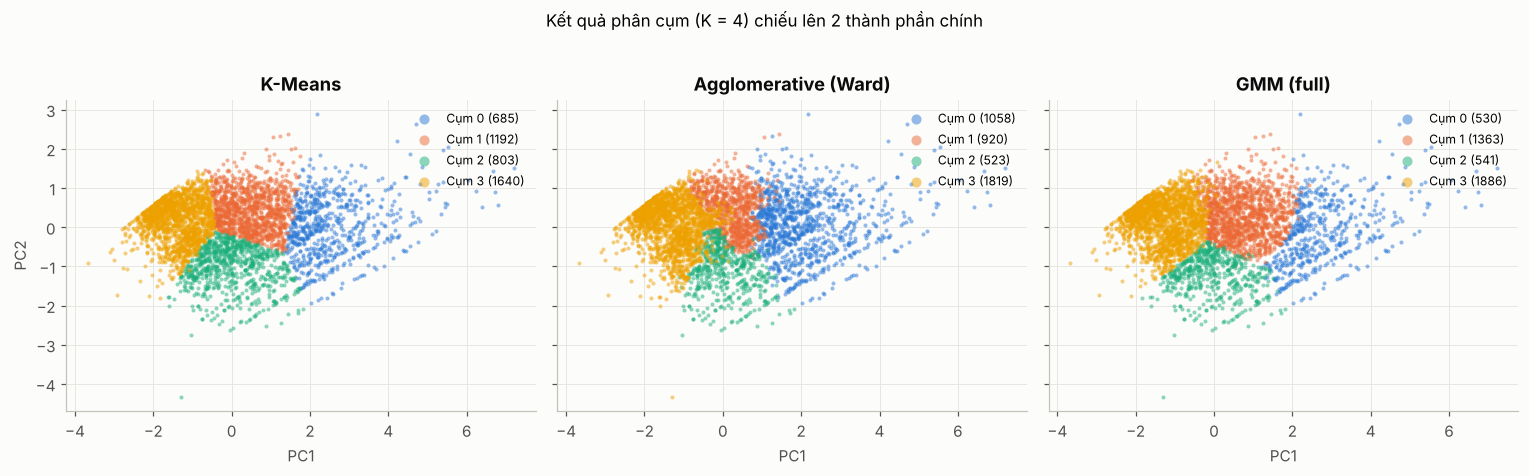

In [17]:
pca = PCA(n_components=2, random_state=SEED).fit(Xv)
P = pca.transform(Xv)
print("Phương sai giải thích bởi PC1, PC2:", np.round(pca.explained_variance_ratio_, 3),
      "| hệ số tải (loadings):"); display(pd.DataFrame(pca.components_, columns=X.columns, index=["PC1", "PC2"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes, [("K-Means", km_lab), ("Agglomerative (Ward)", hc_lab), ("GMM (full)", gm_lab)]):
    for c in range(K):
        m = lab == c
        ax.scatter(P[m, 0], P[m, 1], s=7, alpha=.5, color=viz.PALETTE[c], linewidths=0, label=f"Cụm {c} ({m.sum()})")
    ax.set_title(name); ax.set_xlabel("PC1")
    ax.legend(fontsize=8, markerscale=2.5, loc="upper right")
axes[0].set_ylabel("PC2")
fig.suptitle("Kết quả phân cụm (K = 4) chiếu lên 2 thành phần chính", y=1.02, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig23_clusters_pca"); plt.show()

### 6.3 Hồ sơ cụm (cluster profiling) và đặt tên phân khúc

In [18]:
profiles = {}
for name, lab in [("K-Means", km_lab), ("Agglomerative (Ward)", hc_lab), ("GMM (full)", gm_lab)]:
    p = profile(rfm, lab)
    p.insert(0, "Tên phân khúc", p.index.map(name_clusters(X, lab)))
    profiles[name] = p
    print(f"\n=== {name} ==="); display(p)


=== K-Means ===


,Tên phân khúc,Số khách,Recency (trung vị),Frequency (trung vị),Monetary (trung vị),Monetary TB,% khách,% doanh thu
Cluster,,,,,,,,
0,Champions (VIP),685,8.000,10.000,"3,622.950","7,736.318",15.856,64.082
1,Trung thành – cần chăm sóc,1192,52.000,4.000,"1,312.845","1,667.038",27.593,24.029
2,Khách mới,803,16.000,2.000,460.640,539.869,18.588,5.242
3,Ngủ đông / Rời bỏ,1640,173.000,1.000,288.785,335.144,37.963,6.646



=== Agglomerative (Ward) ===


,Tên phân khúc,Số khách,Recency (trung vị),Frequency (trung vị),Monetary (trung vị),Monetary TB,% khách,% doanh thu
Cluster,,,,,,,,
0,Champions (VIP),1058,11.000,8.000,"2,740.865","5,766.724",24.491,73.778
1,Trung thành – cần chăm sóc,920,64.000,3.000,"1,014.545","1,325.381",21.296,14.745
2,Khách mới,523,11.000,2.000,447.680,515.952,12.106,3.263
3,Ngủ đông / Rời bỏ,1819,140.000,1.000,291.360,373.420,42.106,8.214



=== GMM (full) ===


,Tên phân khúc,Số khách,Recency (trung vị),Frequency (trung vị),Monetary (trung vị),Monetary TB,% khách,% doanh thu
Cluster,,,,,,,,
0,Champions (VIP),530,4.000,11.000,"4,002.250","8,915.448",12.269,57.139
1,Trung thành – cần chăm sóc,1363,36.000,4.000,"1,386.580","1,840.366",31.551,30.333
2,Khách mới,541,12.000,2.000,383.030,471.243,12.523,3.083
3,Ngủ đông / Rời bỏ,1886,154.000,1.000,311.700,414.151,43.657,9.445


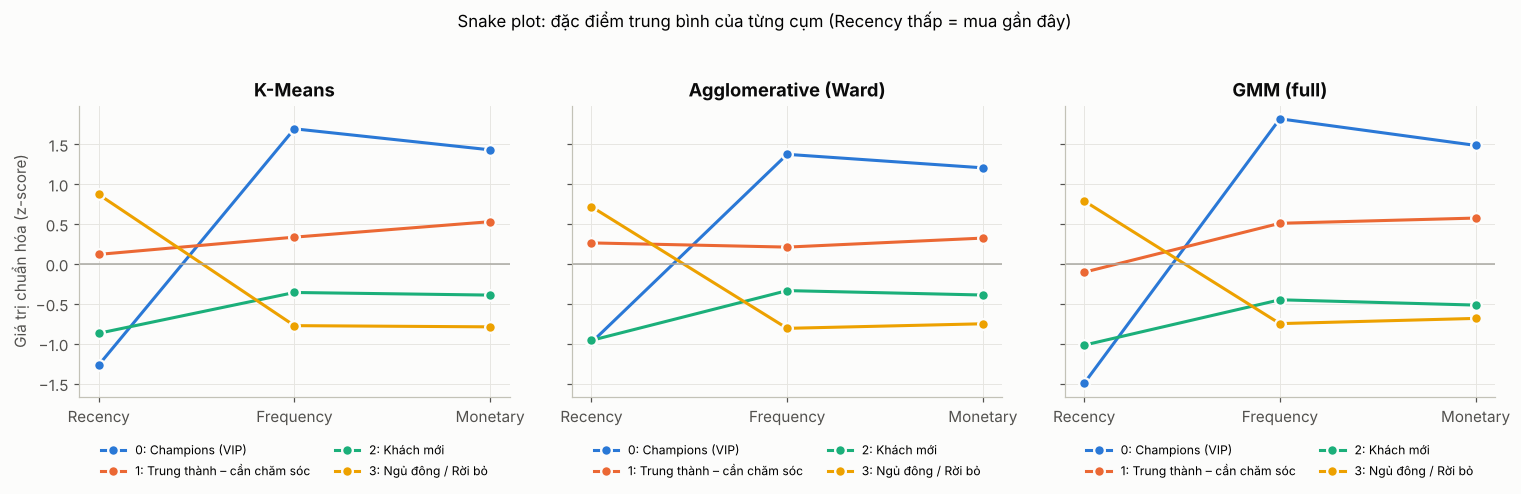

In [19]:
# Snake plot: giá trị trung bình chuẩn hóa của từng cụm trên 3 chiều (K-Means)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, (name, lab) in zip(axes, [("K-Means", km_lab), ("Agglomerative (Ward)", hc_lab), ("GMM (full)", gm_lab)]):
    means = X.assign(c=lab).groupby("c").mean()
    nm = name_clusters(X, lab)
    for c in range(K):
        ax.plot(["Recency", "Frequency", "Monetary"], means.loc[c].values, marker="o", markersize=7,
                color=viz.PALETTE[c], markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=f"{c}: {nm[c]}")
    ax.axhline(0, color=viz.GREY, linewidth=1)
    ax.set_title(name); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2, frameon=False)
axes[0].set_ylabel("Giá trị chuẩn hóa (z-score)")
fig.suptitle("Snake plot: đặc điểm trung bình của từng cụm (Recency thấp = mua gần đây)", y=1.03, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig24_snake_plot"); plt.show()

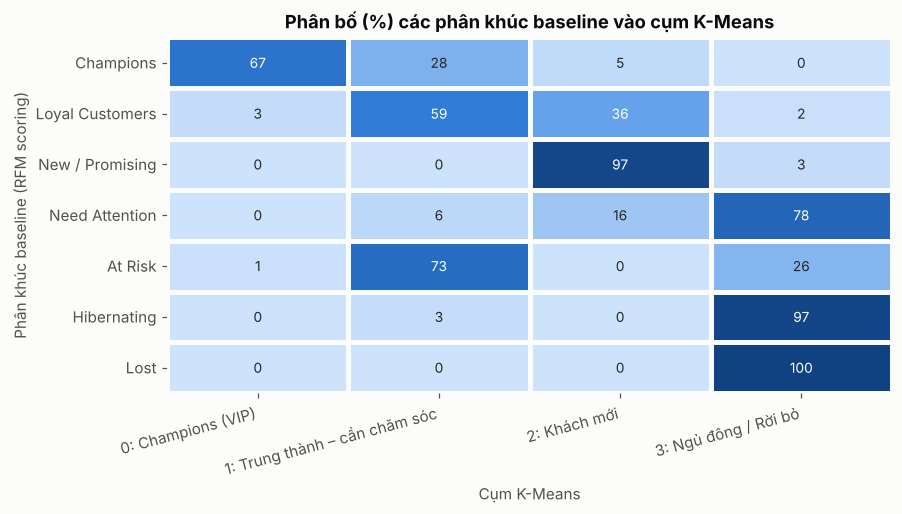

In [20]:
# Đối chiếu cụm K-Means với phân khúc baseline (tỉ lệ % theo hàng)
order = ["Champions", "Loyal Customers", "New / Promising", "Need Attention", "At Risk", "Hibernating", "Lost"]
nm = name_clusters(X, km_lab)
ctab = pd.crosstab(rule, pd.Series(km_lab, index=rule.index).map(lambda c: f"{c}: {nm[c]}"), normalize="index") * 100
ctab = ctab.reindex(order)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.heatmap(ctab, annot=True, fmt=".0f", cmap=viz.SEQ_CMAP, vmin=0, vmax=100, ax=ax, cbar=False,
            linewidths=2, linecolor="#fcfcfb", annot_kws={"size": 9})
ax.set_xlabel("Cụm K-Means"); ax.set_ylabel("Phân khúc baseline (RFM scoring)")
ax.set_title("Phân bố (%) các phân khúc baseline vào cụm K-Means")
plt.xticks(rotation=15, ha="right")
viz.save(fig, "fig25_kmeans_vs_rule"); plt.show()

**Nhận xét – diễn giải phân khúc:**
- Cả ba thuật toán đều cho ra **cùng bốn chân dung khách hàng**. Snake plot của ba thuật toán gần như trùng nhau về hình dạng:

| Phân khúc (theo K-Means) | % khách | % doanh thu | Đặc điểm (trung vị) | Gợi ý hành động |
|---|---|---|---|---|
| **0 – Champions (VIP)** | 15,9% | **64,1%** | Mua cách đây 8 ngày, 10 đơn, khoảng 3.623 £ | Chương trình khách hàng thân thiết, ưu đãi độc quyền, giới thiệu sản phẩm mới trước |
| **1 – Trung thành, cần chăm sóc** | 27,6% | 24,0% | 52 ngày, 4 đơn, khoảng 1.313 £ | Upsell/cross-sell, nhắc mua lại; đây là nhóm có tiềm năng lên VIP |
| **2 – Khách mới** | 18,6% | 5,2% | 16 ngày, 2 đơn, khoảng 461 £ | Chuỗi email chào mừng, ưu đãi cho đơn thứ hai/thứ ba |
| **3 – Ngủ đông / Rời bỏ** | 38,0% | 6,6% | 173 ngày, 1 đơn, khoảng 289 £ | Chiến dịch win-back chi phí thấp, hoặc chấp nhận để rời đi |

- **Khác biệt giữa các thuật toán:** Ward cho nhóm VIP **rộng hơn** (24,5% khách, 73,8% doanh thu), còn GMM cho nhóm VIP **hẹp hơn** (12,3% khách, 57,1% doanh thu, nhưng trung vị Recency chỉ 4 ngày và 11 đơn). Như vậy, việc chọn thuật toán ảnh hưởng trực tiếp tới **quy mô** của nhóm được ưu đãi, và do đó tới chi phí marketing.
- **Đối chiếu với baseline:** New/Promising (97%), Hibernating (97%) và Lost (100%) khớp gần như hoàn toàn với một cụm K-Means. Nhóm **At Risk** của baseline (73%) chủ yếu rơi vào cụm "Trung thành, cần chăm sóc". Điều đó cho thấy cụm 1 thực chất gồm cả khách trung thành bình thường lẫn khách giá trị đang chậm lại, và đây là nơi nên kết hợp thêm thông tin Recency khi triển khai. Nhóm **Champions** của baseline bị chia giữa cụm VIP (67%) và cụm 1 (28%): K-Means khắt khe hơn khi xếp hạng VIP.

## 7. Thử nghiệm bổ sung: bộ đặc trưng RFM mở rộng (6 chiều)
Đầu vào là `rfm_ext_input.csv` (R, F, M, Tenure, AOV, NumProducts; đã biến đổi Yeo-Johnson và chuẩn hóa). Mục tiêu là trả lời câu hỏi: thêm đặc trưng có giúp cụm tách biệt tốt hơn, hoặc làm thay đổi cách phân khúc hay không?

In [21]:
Xe = pd.read_csv(OUT / "rfm_ext_input.csv", index_col=0).values
rows = []
for name, mk, lab3 in [
    ("K-Means", lambda: KMeans(n_clusters=K, n_init=10, random_state=SEED), km_lab),
    ("Agglomerative (Ward)", lambda: AgglomerativeClustering(n_clusters=K, linkage="ward"), hc_lab),
    ("GMM (full)", lambda: GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=SEED, reg_covar=REG), gm_lab),
]:
    _, lab, t = timed_fit(mk, Xe)
    m3 = cmp.loc[name]
    rows.append({"Thuật toán": name, "Silhouette (3D)": m3["Silhouette"], **{f"{k} (6D)": v for k, v in internal_metrics(Xe, lab).items()},
                 "ARI so với kết quả 3D": agreement(lab, lab3)["ARI"]})
ext_cmp = pd.DataFrame(rows).set_index("Thuật toán")
ext_cmp

,Silhouette (3D),Silhouette (6D),Davies-Bouldin (6D),Calinski-Harabasz (6D),ARI so với kết quả 3D
Thuật toán,,,,,
K-Means,0.339,0.256,1.288,"1,802.528",0.247
Agglomerative (Ward),0.269,0.168,1.570,"1,377.885",0.290
GMM (full),0.337,0.163,1.541,"1,136.870",0.356


**Nhận xét – bộ đặc trưng mở rộng 6 chiều:**
- Silhouette giảm ở cả ba thuật toán (K-Means từ 0,339 xuống 0,256; Ward và GMM xuống khoảng 0,16–0,17), còn Davies-Bouldin tăng. Cần lưu ý rằng chỉ số tính trong hai không gian có số chiều khác nhau thì **không so sánh trực tiếp được hoàn toàn**: khoảng cách trong không gian nhiều chiều có xu hướng "đều" hơn (hiện tượng curse of dimensionality).
- ARI giữa kết quả 6D và 3D chỉ 0,25–0,36. Nghĩa là thêm Tenure, AOV và NumProducts **làm thay đổi đáng kể cách phân nhóm**: mô hình bắt đầu chia khách theo "quy mô đơn hàng" (AOV) và "độ lâu năm" (Tenure) thay vì chỉ theo RFM.
- → Nhóm giữ **RFM 3 chiều làm cấu hình chính**, vì cụm tách biệt tốt hơn và dễ diễn giải hơn. Các đặc trưng mở rộng được dùng để **mô tả thêm** hồ sơ cụm. Khả năng kết hợp nhiều đặc trưng sẽ được thử lại ở notebook 04 với các phương pháp học biểu diễn (UMAP/Autoencoder), vốn phù hợp hơn với dữ liệu nhiều chiều.

## 8. Lưu kết quả

In [22]:
labels_df = pd.DataFrame({"KMeans": km_lab, "Agglomerative": hc_lab, "GMM": gm_lab, "GMM_maxproba": maxp}, index=X.index)
labels_df.to_csv(OUT / "labels_classic.csv")
cmp.to_csv(OUT / "metrics_classic.csv")
pd.concat({k: v for k, v in profiles.items()}).to_csv(OUT / "profiles_classic.csv")
km_scan.to_csv(OUT / "scan_kmeans.csv"); hc_scan.to_csv(OUT / "scan_hierarchical.csv"); gm_scan.to_csv(OUT / "scan_gmm.csv", index=False)
print("Đã lưu:", ", ".join(sorted(p.name for p in OUT.glob("*classic*"))), "+ scan_*.csv")

Đã lưu: labels_classic.csv, metrics_classic.csv, profiles_classic.csv + scan_*.csv


## 9. Tổng kết notebook 03

| Thuật toán | Điểm mạnh trên bộ dữ liệu này | Điểm yếu |
|---|---|---|
| **K-Means** | Silhouette và CH cao nhất; nhanh nhất; **ổn định nhất** (ARI 0,95); tâm cụm dễ diễn giải | Phải chọn K trước; giả định cụm hình cầu; gán cứng |
| **Agglomerative (Ward)** | Dendrogram cho cái nhìn phân cấp và gợi ý số cụm; không phụ thuộc khởi tạo ngẫu nhiên | Kém ổn định nhất (ARI 0,44); chậm, tốn bộ nhớ $O(n^2)$; single/average linkage thất bại vì hiệu ứng chuỗi |
| **GMM** | Davies-Bouldin tốt nhất; cụm dạng elip; **xác suất thành viên** giúp nhận diện khách đang "chuyển dịch" | Suy biến với biến đếm rời rạc nếu không điều chỉnh `reg_covar`; nhạy với khởi tạo |

**Kết luận chính của notebook 03:**
1. Cả ba thuật toán cổ điển đều tìm ra **cùng một cấu trúc 4 phân khúc**: VIP, Trung thành, Khách mới, Ngủ đông. Điều này tăng độ tin cậy cho kết quả phân khúc.
2. Silhouette chỉ ở mức trung bình (≤ 0,34), xác nhận rằng **khách hàng tạo thành một dải liên tục** chứ không phải các nhóm tách biệt rõ.
3. Với bài toán này, **K-Means là lựa chọn cân bằng nhất** giữa chất lượng, tốc độ, độ ổn định và khả năng diễn giải.
4. Hai câu hỏi mở cho notebook 04: (a) liệu thuật toán dựa trên mật độ (HDBSCAN) có tìm ra cấu trúc tự nhiên mà không cần chọn K hay không, và có tách riêng nhóm khách bán buôn cực lớn hay không; (b) liệu học biểu diễn (UMAP/Autoencoder) có khai thác được bộ đặc trưng mở rộng tốt hơn hay không.